# 1

### Nota: 10

En este ejercicio queremos que realices un análisis exploratorio de datos semanales de ventas, identificando valores nulos y outliers, calculando correlaciones entre variables, y visualizando la relación entre el precio y las unidades vendidas mediante un gráfico de dispersión, utilizando Pandas.

semana               0
unidades_vendidas    0
precio               0
publicidad_1         0
oferta_1             8
dtype: int64


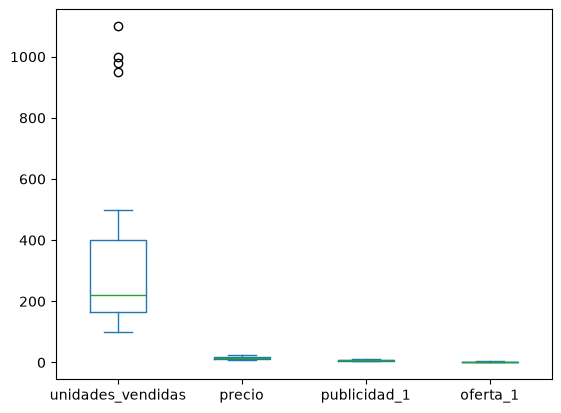

                   unidades_vendidas    precio  publicidad_1
unidades_vendidas           1.000000  0.695364      0.505473
precio                      0.695364  1.000000      0.722081
publicidad_1                0.505473  0.722081      1.000000


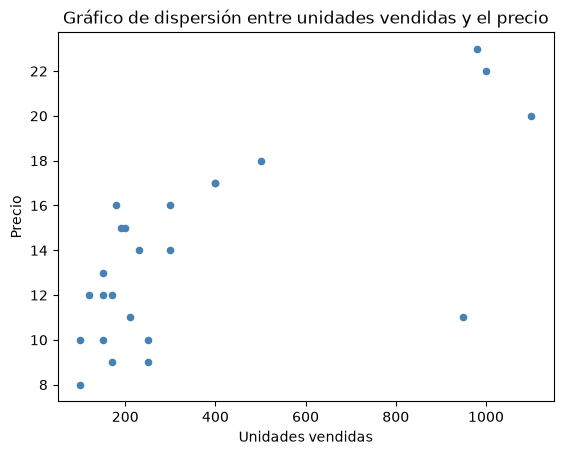

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api

data = [
    {"semana": "2023-01-01", "unidades_vendidas": 100, "precio": 8, "publicidad_1": 5, "oferta_1": None},
    {"semana": "2023-01-08", "unidades_vendidas": 200, "precio": 15, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-01-15", "unidades_vendidas": 950, "precio": 11, "publicidad_1": 6, "oferta_1": 3},
    {"semana": "2023-01-22", "unidades_vendidas": 150, "precio": 10, "publicidad_1": 7, "oferta_1": 1},
    {"semana": "2023-01-29", "unidades_vendidas": 1100, "precio": 20, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-02-05", "unidades_vendidas": 120, "precio": 12, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-02-12", "unidades_vendidas": 250, "precio": 9, "publicidad_1": 8, "oferta_1": 1},
    {"semana": "2023-02-19", "unidades_vendidas": 300, "precio": 14, "publicidad_1": 7, "oferta_1": None},
    {"semana": "2023-02-26", "unidades_vendidas": 400, "precio": 17, "publicidad_1": 9, "oferta_1": 3},
    {"semana": "2023-03-05", "unidades_vendidas": 150, "precio": 13, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-03-12", "unidades_vendidas": 100, "precio": 10, "publicidad_1": 6, "oferta_1": None},
    {"semana": "2023-03-19", "unidades_vendidas": 500, "precio": 18, "publicidad_1": 10, "oferta_1": 4},
    {"semana": "2023-03-26", "unidades_vendidas": 180, "precio": 16, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-04-02", "unidades_vendidas": 170, "precio": 12, "publicidad_1": 7, "oferta_1": 1},
    {"semana": "2023-04-09", "unidades_vendidas": 1000, "precio": 22, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-04-16", "unidades_vendidas": 210, "precio": 11, "publicidad_1": 5, "oferta_1": 3},
    {"semana": "2023-04-23", "unidades_vendidas": 230, "precio": 14, "publicidad_1": 8, "oferta_1": 2},
    {"semana": "2023-04-30", "unidades_vendidas": 190, "precio": 15, "publicidad_1": 6, "oferta_1": 1},
    {"semana": "2023-05-07", "unidades_vendidas": 300, "precio": 16, "publicidad_1": 9, "oferta_1": 4},
    {"semana": "2023-05-14", "unidades_vendidas": 250, "precio": 10, "publicidad_1": 7, "oferta_1": None},
    {"semana": "2023-05-21", "unidades_vendidas": 400, "precio": 17, "publicidad_1": 10, "oferta_1": 3},
    {"semana": "2023-05-28", "unidades_vendidas": 980, "precio": 23, "publicidad_1": 9, "oferta_1": None},
    {"semana": "2023-06-04", "unidades_vendidas": 150, "precio": 12, "publicidad_1": 5, "oferta_1": 2},
    {"semana": "2023-06-11", "unidades_vendidas": 170, "precio": 9, "publicidad_1": 6, "oferta_1": None}
]

# Creamos el DataFrame y convertimos la columna de semana en datetime
df = pd.DataFrame(data)
df["semana"] = pd.to_datetime(df["semana"])

# Primero identificamos los valores nulos
print(df.isna().sum())

# Hay 8 valores nulos en oferta_1, primero aplicamos un forward fill, y luego un backward para el primer valor
df = df.assign(oferta_1 = lambda x: x.oferta_1.ffill())
df = df.assign(oferta_1 = lambda x: x.oferta_1.bfill())

# Vemos los outliers que existen en unidades_vendidas
df.plot.box()
plt.show()

# Calculamos el coeficiente de correlación de Pearson para el DataFrame
pearson_corr = df[["unidades_vendidas", "precio", "publicidad_1"]].corr(method = "pearson")
print(pearson_corr)

# Hacemos el gráfico entre las unidades vendidas y el precio para ver la correlación de 0.69
df.plot(x = "unidades_vendidas", y = "precio", kind = "scatter", c = "steelblue")
plt.title("Gráfico de dispersión entre unidades vendidas y el precio")
plt.xlabel("Unidades vendidas")
plt.ylabel("Precio")
plt.show()

# 2

### Nota: 9.3

En este proyecto, eres un analista de datos encargado de analizar las ventas de entradas de cine y eventos promocionales. Tu objetivo es combinar dos conjuntos de datos (ventas y promociones), identificar patrones y entrenar un modelo de regresión lineal para predecir las ventas semanales de boletos. Esto ayudará a optimizar las estrategias de marketing y mejorar las decisiones comerciales.

In [97]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

work_dir = "../media/0_lab4/"
ventas_dir = "ventas_peliculas.csv"
promocion_dir = "promocion_peliculas.csv"

Cargamos los datos

In [37]:
ventas = pd.read_csv(work_dir + ventas_dir)
prom = pd.read_csv(work_dir + promocion_dir)

Hacemos un left join sobre las claves fecha y titulo.

In [ ]:
df = ventas.merge(prom, how = "left", on = ("fecha", "titulo"), validate = "1:m")

In [72]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 40 entries, 0 to 39
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   fecha                    40 non-null     datetime64[us]
 1   titulo                   40 non-null     str           
 2   ventas_boletos           40 non-null     int64         
 3   calificacion             40 non-null     float64       
 4   eventos_promocionales    40 non-null     int64         
 5   participacion_promocion  40 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(1)
memory usage: 2.0 KB


Convertimos la fecha a datetime

In [74]:
df["fecha"] = pd.to_datetime(df["fecha"])
df = df.set_index(["fecha"])

In [76]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 40 entries, 2022-01-02 to 2022-10-02
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   titulo                   40 non-null     str    
 1   ventas_boletos           40 non-null     int64  
 2   calificacion             40 non-null     float64
 3   eventos_promocionales    40 non-null     int64  
 4   participacion_promocion  40 non-null     float64
dtypes: float64(2), int64(2), str(1)
memory usage: 1.9 KB


Comprobemos valores nulos.

In [46]:
df.isna().sum()

fecha                      0
titulo                     0
ventas_boletos             0
calificacion               0
eventos_promocionales      0
participacion_promocion    0
dtype: int64

No hay ningún valor nulo. Comprobemos que la frecuencia de fecha es semanal:

In [109]:
df.asfreq("w").head()

/tmp/ipykernel_16405/2259730616.py:1: Pandas4Warning: 'w' is deprecated and will be removed in a future version, please use 'W' instead.
  df.asfreq("w").head()


,titulo,ventas_boletos,calificacion,eventos_promocionales,participacion_promocion,media_semanal_ventas,predicciones
fecha,,,,,,,
2022-01-02,Pelicula A,500,7.8,3,0.85,NaN,552.136609
2022-01-09,Pelicula B,600,8.2,2,0.70,550.0,622.454720
2022-01-16,Pelicula C,450,6.5,4,0.90,525.0,427.125643
2022-01-23,Pelicula D,700,9.0,1,0.75,575.0,661.038667
2022-01-30,Pelicula A,480,7.9,2,0.80,590.0,556.187683


Obtenemos el mismo DataFrame, así que, en efecto, fecha tiene una frecuencia semanal, para hacer un gráfico de las ventas de boletos semanales simplemente hemos de graficar venta_boletos frente a fecha

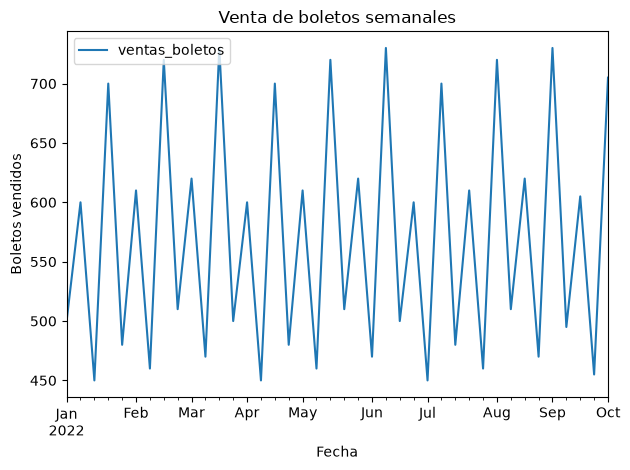

In [93]:
df.plot.line(y = "ventas_boletos")
plt.title("Venta de boletos semanales")
plt.xlabel("Fecha")
plt.ylabel("Boletos vendidos")
plt.legend(loc = "upper left")
plt.tight_layout()

El promedio semanal lo hacemos con el promedio entre el valor de la semana anterior y la presente:

In [123]:
df["media_semanal_ventas"] = df.ventas_boletos.rolling(window = 2).mean()
df.head()

,titulo,ventas_boletos,calificacion,eventos_promocionales,participacion_promocion,media_semanal_ventas,predicciones,media_no_eventos
fecha,,,,,,,,
2022-01-02,Pelicula A,500,7.8,3,0.85,NaN,554.618579,NaN
2022-01-09,Pelicula B,600,8.2,2,0.70,550.0,616.870688,NaN
2022-01-16,Pelicula C,450,6.5,4,0.90,525.0,425.619499,NaN
2022-01-23,Pelicula D,700,9.0,1,0.75,575.0,666.675597,NaN
2022-01-30,Pelicula A,480,7.9,2,0.80,590.0,558.525252,NaN


La media las semanas que no hay eventos será siempre un valor nulo, porque el valor mínimo de eventos en el dataset es 1, aún así se construye la columna.

In [124]:
df["media_no_eventos"] = df.loc[df.eventos_promocionales == 0].ventas_boletos.rolling(window = 2).mean()


<Axes: xlabel='media_semanal_ventas'>

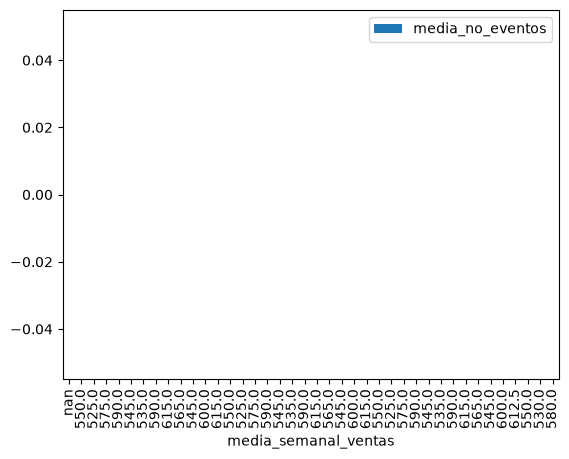

In [125]:
df.plot.bar(x = "media_semanal_ventas", y = "media_no_eventos")

Por lo que no se ve nada en el gráfico.

Hacemos un boxplot para ver posibles outliers en las ventas de boletos

<Axes: >

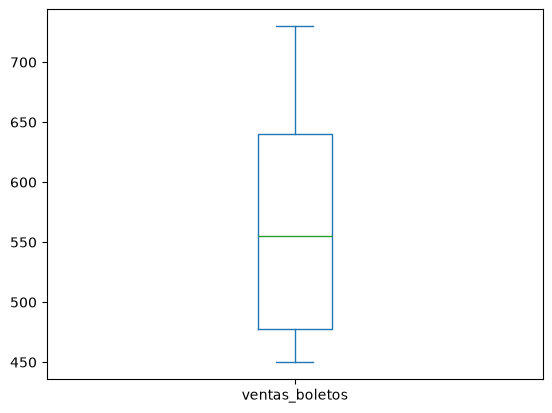

In [126]:
df["ventas_boletos"].plot.box()

No hay outliers en este caso.

Veamos la correlación entre las ventas de boletos, la calificación, los eventos promocionales, y la participación en la promoción

In [96]:
corr = df[["ventas_boletos", "calificacion", "eventos_promocionales", "participacion_promocion"]].corr(method = "pearson")
corr

,ventas_boletos,calificacion,eventos_promocionales,participacion_promocion
ventas_boletos,1.000000,0.891084,-0.024186,-0.222780
calificacion,0.891084,1.000000,-0.112398,-0.254830
eventos_promocionales,-0.024186,-0.112398,1.000000,0.829671
participacion_promocion,-0.222780,-0.254830,0.829671,1.000000


Las ventas de boletos están estrechamente correlacionadas con la calificación. Entrenemos ahora un modelo para hacer regresión, del tipo OLS

In [ ]:
predictors = df[["calificacion", "eventos_promocionales", "participacion_promocion"]]
predictors["intercept"] = 1
target = df["ventas_boletos"]


rl = sm.OLS(target, predictors)
rl = rl.fit()

In [111]:
predictions = rl.predict(predictors)

In [112]:
df["predicciones"] = predictions

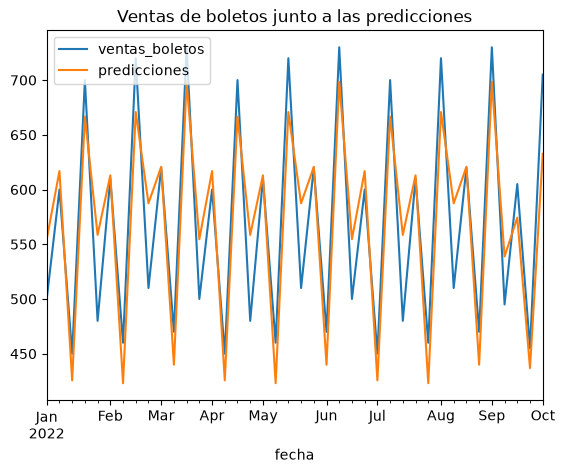

In [113]:
df.plot(y = ["ventas_boletos", "predicciones"])
plt.title("Ventas de boletos junto a las predicciones")
plt.legend(loc = "upper left")

Hagamos ahora un resumen del modelo

In [114]:
rl.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         ventas_boletos   R-squared:                       0.811
Model:                            OLS   Adj. R-squared:                  0.796
Method:                 Least Squares   F-statistic:                     51.63
Date:                Sun, 22 Nov 2026   Prob (F-statistic):           4.03e-13
Time:                        16:22:30   Log-Likelihood:                -207.98
No. Observations:                  40   AIC:                             424.0
Df Residuals:                      36   BIC:                             430.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
===========================================================================================
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
calificacion              104.2437      9.157     11.384      0.000      85.673     122.815
eventos_promocionales      20.0539     11.019      1.820      0.077      -2.293      42.401
participacion_promocion  -270.7233    182.506     -1.483      0.147    -640.863      99.416
intercept                 -88.5288    160.521     -0.552      0.585    -414.080     237.022
==============================================================================
Omnibus:                        5.446   Durbin-Watson:                   2.175
Prob(Omnibus):                  0.066   Jarque-Bera (JB):                4.064
Skew:                          -0.647   Prob(JB):                        0.131
Kurtosis:                       2.126   Cond. No.                         275.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Se obtiene un valor de R² $\approx$ 0.8.